# Chimera v2.4 — α / Δα biological enrichment

This notebook grounds Chimera's two first-class outputs in biology:

- **α** — per-gene integration coefficient, how much the shared (species-
  agnostic) decoder explains the gene's expression.
- **Δα = α − prior** — how much the trained model corrects the sequence-
  conservation prior. **Positive Δα** = gene is more *expression-conserved*
  than its protein sequence predicts; **negative Δα** = the opposite.

The narrative we want to support: **α and Δα track biologically meaningful
categories**. Housekeeping, ribosomal, histone, and mitochondrial genes should
sit at high α; interferon-stimulated and immediate-early genes (well-known
for species-divergent regulation) should sit at lower α and/or have
negative Δα.

### Category definitions (transparent, minimal)

All categories are defined in [`_paper_utils`](_paper_utils.py)
`classify_gene_category`. Prefix-based rules take priority over curated lists:

| Category | Definition |
|---|---|
| `ribosomal` | symbols starting with `RPL`/`RPS`/`MRPL`/`MRPS` |
| `histone` | `HIST*`, `H1-*`, `H2A*`, `H2B*`, `H3-*`, `H4-*`, `H1F*` |
| `mitochondrial` | `MT-*`, `MTRNR*`, `MTATP*`, `MTCO*`, `MTCY*`, `MTND*` |
| `housekeeping` | short canonical list (Eisenberg & Levanon 2013 top tier) |
| `cell_cycle` | canonical Tirosh et al. 2016 cell-cycle markers |
| `interferon` | canonical type-I IFN response genes |
| `immediate_early` | canonical IEGs (FOS, JUN, EGR family, ...) |
| `other` | everything else |

A more ambitious enrichment analysis (GO-BP, MsigDB Hallmarks) is a drop-in
on the exported ranked gene tables from §4/§5, without touching the model.

### Sections

1. Category annotation + coverage (how many genes per category).
2. α distribution by category.
3. Δα distribution by category.
4. Enrichment tests: top/bottom 10% α × category; top/bottom 10% Δα × category.
5. Top positive- and negative-Δα genes (with symbols + categories).
6. α versus mean protein identity, coloured by category.
7. Residual magnitude by category.
8. Closing narrative.

**Default run:** `iter16-slow-classifier` (Human + Monkey, 32/32).
Change `RUN_NAME` to analyse a different run.


In [1]:
import sys, warnings
from pathlib import Path

HERE = Path.cwd()
sys.path.insert(0, str(HERE))
warnings.filterwarnings("ignore", category=UserWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats as spstats

import _paper_utils as pu
pu.set_paper_style()

RUN_NAME = "iter16-slow-classifier"
TOP_FRAC = 0.10    # top/bottom 10% for enrichment tests
SAVE_FIGS = False

run = pu.load_run(RUN_NAME)
adata = pu.load_adata_for_run(run)
fs = run["final_state"]

alpha = fs["alpha"]
prior = fs["prior"]
dalpha = alpha - prior
residual_rms = fs["residual_rms"]

# Gene category annotation
cat_df = pu.annotate_gene_categories(adata.var_names)
gene_df = pd.DataFrame({
    "symbol": cat_df["symbol"].values,
    "category": cat_df["category"].values,
    "alpha": alpha,
    "prior": prior,
    "dalpha": dalpha,
    "residual_rms": residual_rms,
})

# Ortholog table for mean_identity (the raw data that backs `prior`)
ot = pu.load_ortholog_table()
og_ids = adata.var_names.str.extract(r"ortho_(\d+)")[0].astype("float").astype("Int64")
gene_df["mean_identity"] = og_ids.map(ot["mean_identity"]).values

print(f"run={RUN_NAME}  genes={len(gene_df)}  mean(alpha)={alpha.mean():.3f}  "
      f"mean(prior)={prior.mean():.3f}  mean(Δα)={dalpha.mean():.3f}")


run=iter16-slow-classifier  genes=8430  mean(alpha)=0.788  mean(prior)=0.800  mean(Δα)=-0.012


## §1 — Gene-category coverage

Fisher enrichment is only meaningful when a category has enough genes in
the dataset to give a stable test. Categories with fewer than ~5 genes are
flagged but kept in the plots.


                 n_genes  frac_of_total
ribosomal            100         0.0119
mitochondrial          9         0.0011
histone                4         0.0005
housekeeping          10         0.0012
cell_cycle            24         0.0028
immediate_early       11         0.0013
interferon             5         0.0006
other               8267         0.9807


/var/folders/y7/7c17s0l57szdjc1cdc9dmnpm0000gn/T/ipykernel_99466/4172209044.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=counts.values, y=counts.index, ax=ax, palette=palette)


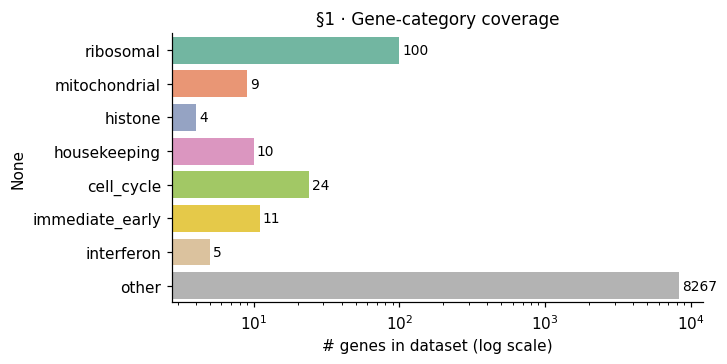

In [2]:
counts = gene_df["category"].value_counts().reindex(pu.CATEGORY_ORDER, fill_value=0)
total = len(gene_df)
cov = pd.DataFrame({
    "n_genes": counts.values,
    "frac_of_total": counts.values / total,
}, index=counts.index)
print(cov.round(4).to_string())

fig, ax = plt.subplots(figsize=(6.5, 3.2))
palette = sns.color_palette("Set2", n_colors=len(pu.CATEGORY_ORDER))
sns.barplot(x=counts.values, y=counts.index, ax=ax, palette=palette)
ax.set_xscale("log")
ax.set_xlabel("# genes in dataset (log scale)")
ax.set_title("§1 · Gene-category coverage")
for i, (cat, n) in enumerate(counts.items()):
    ax.text(max(n * 1.05, 1.1), i, str(n), va="center", fontsize=9)
if SAVE_FIGS:
    fig.savefig(f"figs/nb13_{RUN_NAME}_coverage.png", bbox_inches='tight')
plt.show()


## §2 — α distribution by category

**Hypothesis.** Biologically-conserved, cross-cell-type-expressed categories
(housekeeping, ribosomal, mitochondrial, histone) should sit at **high α**.
Species-divergent / context-specific categories (interferon-response,
immediate-early) should sit at **lower α**. Cell-cycle should sit somewhere
in between (conserved across cell types but dynamic in expression).

A boxplot shows the per-category distribution; horizontal line = global α
median for context.


/var/folders/y7/7c17s0l57szdjc1cdc9dmnpm0000gn/T/ipykernel_99466/4098335735.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=plot_df, x="category", y="alpha", ax=ax,


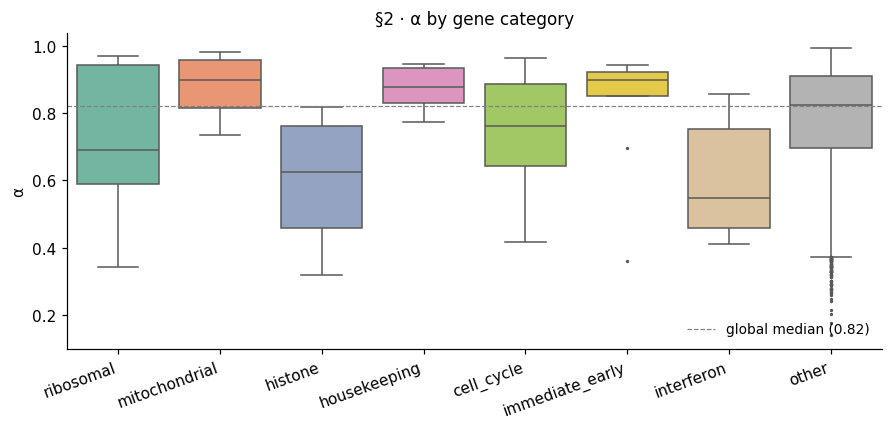

                 median   mean    std  count
category                                    
mitochondrial     0.899  0.886  0.088      9
other             0.823  0.789  0.150   8267
ribosomal         0.690  0.730  0.181    100
immediate_early   0.898  0.834  0.171     11
cell_cycle        0.761  0.750  0.144     24
histone           0.625  0.597  0.228      4
housekeeping      0.878  0.874  0.064     10
interferon        0.549  0.606  0.192      5


In [3]:
cats_present = [c for c in pu.CATEGORY_ORDER if (gene_df["category"] == c).sum() >= 3]
plot_df = gene_df[gene_df["category"].isin(cats_present)].copy()
plot_df["category"] = pd.Categorical(plot_df["category"], categories=cats_present)

fig, ax = plt.subplots(figsize=(8, 3.8))
sns.boxplot(data=plot_df, x="category", y="alpha", ax=ax,
            order=cats_present, palette="Set2", fliersize=1.2, showfliers=True)
ax.axhline(gene_df["alpha"].median(), color="grey", ls="--", lw=0.8,
           label=f"global median ({gene_df['alpha'].median():.2f})")
ax.set_ylabel("α")
ax.set_xlabel("")
ax.set_title("§2 · α by gene category")
ax.set_xticklabels(ax.get_xticklabels(), rotation=20, ha="right")
ax.legend(loc="lower right")
if SAVE_FIGS:
    fig.savefig(f"figs/nb13_{RUN_NAME}_alpha_by_cat.png", bbox_inches='tight')
plt.show()

# Per-category medians with global context
med_tbl = plot_df.groupby("category", observed=True)["alpha"].agg(
    ["median", "mean", "std", "count"]).round(3)
print(med_tbl.to_string())


## §3 — Δα distribution by category

**Hypothesis.** Δα > 0 genes = model *promotes* integration beyond the
sequence-identity prior (expression-conserved despite sequence divergence).
Δα < 0 = model *demotes* integration (expression-divergent despite
sequence conservation). Interferon-response and immediate-early genes are
classical species-divergent-regulation categories and should shift **left**
(Δα < 0 enriched). Housekeeping / ribosomal / histone genes should shift
**right** (Δα > 0 enriched).

Per-category mean Δα with Wilcoxon one-sample tests against zero (does this
category's Δα distribution differ from zero?).


/var/folders/y7/7c17s0l57szdjc1cdc9dmnpm0000gn/T/ipykernel_99466/2926687187.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=plot_df, x="category", y="dalpha", ax=ax,


                    n  mean_Δα  median_Δα  frac_Δα>0  frac_Δα<0  wilcoxon_p
category                                                                   
ribosomal         100  -0.0911    -0.0885     0.2200     0.7800      0.0000
mitochondrial       9   0.1635     0.1697     1.0000     0.0000      0.0039
histone             4  -0.1270    -0.1401     0.0000     1.0000      0.1250
housekeeping       10  -0.0120    -0.0287     0.3000     0.7000      0.4922
cell_cycle         24  -0.0787    -0.0741     0.0833     0.9167      0.0000
immediate_early    11   0.0141     0.0314     0.8182     0.1818      0.2061
interferon          5  -0.0586    -0.0724     0.2000     0.8000      0.6250
other            8267  -0.0112    -0.0074     0.4630     0.5370      0.0000


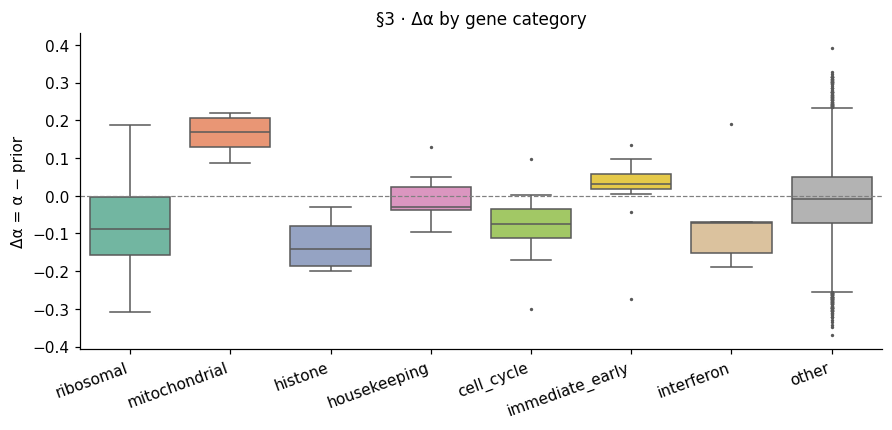

In [4]:
rows = []
for cat in cats_present:
    vals = plot_df.loc[plot_df["category"] == cat, "dalpha"].values
    if len(vals) < 3:
        continue
    stat, pval = spstats.wilcoxon(vals, zero_method="wilcox",
                                  alternative="two-sided", mode="auto")
    rows.append({
        "category": cat,
        "n": len(vals),
        "mean_Δα": float(vals.mean()),
        "median_Δα": float(np.median(vals)),
        "frac_Δα>0": float((vals > 0).mean()),
        "frac_Δα<0": float((vals < 0).mean()),
        "wilcoxon_p": pval,
    })
dalpha_tbl = pd.DataFrame(rows).set_index("category")
print(dalpha_tbl.round(4).to_string())

fig, ax = plt.subplots(figsize=(8, 3.8))
sns.boxplot(data=plot_df, x="category", y="dalpha", ax=ax,
            order=cats_present, palette="Set2", fliersize=1.2)
ax.axhline(0, color="grey", ls="--", lw=0.8)
ax.set_ylabel("Δα = α − prior")
ax.set_xlabel("")
ax.set_title("§3 · Δα by gene category")
ax.set_xticklabels(ax.get_xticklabels(), rotation=20, ha="right")
if SAVE_FIGS:
    fig.savefig(f"figs/nb13_{RUN_NAME}_dalpha_by_cat.png", bbox_inches='tight')
plt.show()


## §4 — Enrichment of categories in α / Δα tails

For each category, compute a Fisher-exact test: are genes in this category
significantly more (or less) likely to fall in the top/bottom 10% of α (and
of Δα) than chance? Odds ratio > 1 = enrichment; < 1 = depletion.

Four tests per category:
1. **Top-α** (most-integrated genes) — expect housekeeping / ribosomal / etc. enriched.
2. **Bottom-α** (least-integrated) — expect interferon / immediate-early enriched.
3. **Top-Δα** (most model-promoted integration) — positive correction categories.
4. **Bottom-Δα** (most model-demoted integration) — species-divergent categories.

A Bonferroni correction across all (category × test) cells is applied.


In [5]:
# Define hit masks
n = len(gene_df)
k = max(int(TOP_FRAC * n), 1)
order_alpha = np.argsort(gene_df["alpha"].values)
order_dalpha = np.argsort(gene_df["dalpha"].values)
top_alpha = np.zeros(n, bool); top_alpha[order_alpha[-k:]] = True
bot_alpha = np.zeros(n, bool); bot_alpha[order_alpha[:k]] = True
top_dalpha = np.zeros(n, bool); top_dalpha[order_dalpha[-k:]] = True
bot_dalpha = np.zeros(n, bool); bot_dalpha[order_dalpha[:k]] = True
hit_masks = {
    "top_alpha (most integrated)": top_alpha,
    "bot_alpha (least integrated)": bot_alpha,
    "top_dalpha (Δα>0 tail)": top_dalpha,
    "bot_dalpha (Δα<0 tail)": bot_dalpha,
}

rows = []
cat_vec = gene_df["category"].values
for test_name, hit in hit_masks.items():
    for cat in [c for c in pu.CATEGORY_ORDER if c != "other"]:
        in_set = cat_vec == cat
        if in_set.sum() < 3:
            continue
        r = pu.fisher_enrichment(in_set, hit)
        r["test"] = test_name
        r["category"] = cat
        rows.append(r)
enr = pd.DataFrame(rows)

# Bonferroni correction
m = len(enr)
enr["p_bonf"] = np.minimum(enr["p_value"] * m, 1.0)
enr["signif"] = enr["p_bonf"] < 0.05
enr["direction"] = np.where(enr["odds_ratio"] > 1, "enriched", "depleted")
enr_disp = enr[["test", "category", "n_hit_in_set", "n_in_set", "odds_ratio",
                "p_value", "p_bonf", "signif", "direction"]].copy()
enr_disp["odds_ratio"] = enr_disp["odds_ratio"].round(2)
enr_disp["p_value"] = enr_disp["p_value"].apply(lambda p: f"{p:.2e}")
enr_disp["p_bonf"] = enr_disp["p_bonf"].apply(lambda p: f"{p:.2e}")

# Pivot for easier reading
for test_name in hit_masks:
    print(f"=== {test_name} ===")
    sub = enr_disp[enr_disp["test"] == test_name].drop(columns=["test"]).reset_index(drop=True)
    print(sub.to_string(index=False))
    print()


=== top_alpha (most integrated) ===
       category  n_hit_in_set  n_in_set  odds_ratio  p_value   p_bonf  signif direction
      ribosomal            12       100        1.23 5.01e-01 1.00e+00   False  enriched
  mitochondrial             3         9        4.51 5.29e-02 1.00e+00   False  enriched
        histone             0         4        0.00 1.00e+00 1.00e+00   False  depleted
   housekeeping             0        10        0.00 6.12e-01 1.00e+00   False  depleted
     cell_cycle             1        24        0.39 5.06e-01 1.00e+00   False  depleted
immediate_early             0        11        0.00 6.16e-01 1.00e+00   False  depleted
     interferon             0         5        0.00 1.00e+00 1.00e+00   False  depleted

=== bot_alpha (least integrated) ===
       category  n_hit_in_set  n_in_set  odds_ratio  p_value   p_bonf  signif direction
      ribosomal            18       100        2.00 1.15e-02 3.21e-01   False  enriched
  mitochondrial             0         9       

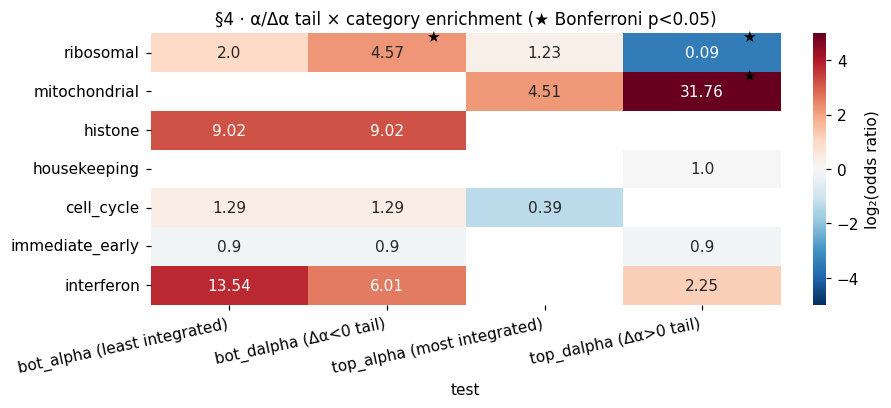

In [6]:
# Heatmap: log2 odds ratio, with significant cells starred.
pivot = enr.pivot_table(index="category", columns="test",
                        values="odds_ratio", aggfunc="first")
# reorder rows to CATEGORY_ORDER (minus 'other')
row_order = [c for c in pu.CATEGORY_ORDER if c in pivot.index and c != "other"]
pivot = pivot.reindex(row_order)

sig_mask = enr.pivot_table(index="category", columns="test",
                           values="signif", aggfunc="first").reindex(row_order)

fig, ax = plt.subplots(figsize=(8, 3.6))
log2_odds = np.log2(pivot.replace(0, np.nan))  # protect against log(0)
vmax = np.nanmax(np.abs(log2_odds.values))
sns.heatmap(log2_odds, cmap="RdBu_r", center=0, vmin=-vmax, vmax=vmax,
            annot=pivot.round(2), fmt="", ax=ax, cbar_kws={"label": "log₂(odds ratio)"})
# annotate significance
for i, cat in enumerate(pivot.index):
    for j, test in enumerate(pivot.columns):
        if sig_mask.loc[cat, test]:
            ax.text(j + 0.8, i + 0.2, "★", color="black", fontsize=10, ha="center")
ax.set_title("§4 · α/Δα tail × category enrichment (★ Bonferroni p<0.05)")
ax.set_ylabel("")
plt.xticks(rotation=12, ha="right")
if SAVE_FIGS:
    fig.savefig(f"figs/nb13_{RUN_NAME}_enrichment.png", bbox_inches='tight')
plt.show()


## §5 — Top positive and negative Δα genes

The individual genes at the Δα tails are the most interpretable output of
Chimera. Positive Δα = model disagrees with the sequence prior in the
direction of *stronger* expression-conservation. Negative Δα = the model
sees species-divergent expression despite sequence conservation.

Column `prior` is the raw sequence-conservation prior; `alpha` is the
learned integration coefficient; `Δα = alpha - prior`; `category` is the
biological category from §1; `|res|` is the mean absolute residual
(species-specific variance left after the shared decoder).


In [7]:
cols = ["symbol", "category", "prior", "alpha", "dalpha", "residual_rms"]
top_pos = gene_df.nlargest(25, "dalpha")[cols].copy()
top_neg = gene_df.nsmallest(25, "dalpha")[cols].copy()
top_pos.columns = ["symbol", "category", "prior", "α", "Δα", "res_rms"]
top_neg.columns = ["symbol", "category", "prior", "α", "Δα", "res_rms"]
print("=== Top 25 positive Δα (model promotes integration beyond prior) ===")
print(top_pos.round(3).to_string(index=False))
print()
print("=== Top 25 negative Δα (model demotes integration despite high prior) ===")
print(top_neg.round(3).to_string(index=False))

# Also export rankings — downstream gseapy / MsigDB can use these directly
(run["run_dir"] / "tables").mkdir(exist_ok=True)
rank_pos_path = run["run_dir"] / "tables" / "ranked_dalpha_top.csv"
rank_neg_path = run["run_dir"] / "tables" / "ranked_dalpha_bot.csv"
top_pos.to_csv(rank_pos_path, index=False)
top_neg.to_csv(rank_neg_path, index=False)
print(f"\nExported top-/bottom-Δα tables to {run['run_dir'] / 'tables'}/")


=== Top 25 positive Δα (model promotes integration beyond prior) ===
 symbol category  prior     α    Δα  res_rms
PDE4DIP    other  0.392 0.784 0.392    0.095
PIK3C2G    other  0.610 0.937 0.327    0.026
 SORBS1    other  0.617 0.940 0.323    0.028
 SORBS2    other  0.627 0.946 0.319    0.057
  APOC1    other  0.627 0.942 0.315    0.046
     C9    other  0.630 0.946 0.315    0.067
    HPX    other  0.600 0.915 0.315    0.035
   TFPI    other  0.610 0.924 0.315    0.062
   AHSG    other  0.574 0.889 0.315    0.020
   COBL    other  0.628 0.937 0.309    0.012
   MLIP    other  0.583 0.892 0.309    0.057
N4BP2L2    other  0.606 0.914 0.308    0.029
  ACYP2    other  0.391 0.699 0.308    0.049
   LIFR    other  0.637 0.943 0.306    0.052
   CLMN    other  0.632 0.937 0.305    0.029
SHROOM3    other  0.645 0.949 0.304    0.050
 IL1RAP    other  0.643 0.946 0.302    0.032
ATF7IP2    other  0.497 0.799 0.302    0.061
 LARP1B    other  0.616 0.917 0.301    0.032
 VPS13B    other  0.626 0.927 0

## §6 — α vs mean protein identity

The conservation prior is a sigmoidal squash of `mean_identity` (averaged
protein sequence identity across species). The scatter below shows α
against `mean_identity`, coloured by category. A Spearman correlation is
printed. **Interpretation**:

- If α tracks identity perfectly (r ≈ 1), Chimera is reproducing the prior
  and not adding information.
- If α is flat vs identity, Chimera has overridden the prior entirely
  (unlikely, given the anchor term).
- What we expect and want: **moderate correlation (0.3–0.6)** with
  *category-specific offsets* — housekeeping / ribosomal genes sit above
  the global regression line (expression is more conserved than sequence
  identity alone predicts); interferon / IEG genes sit below.


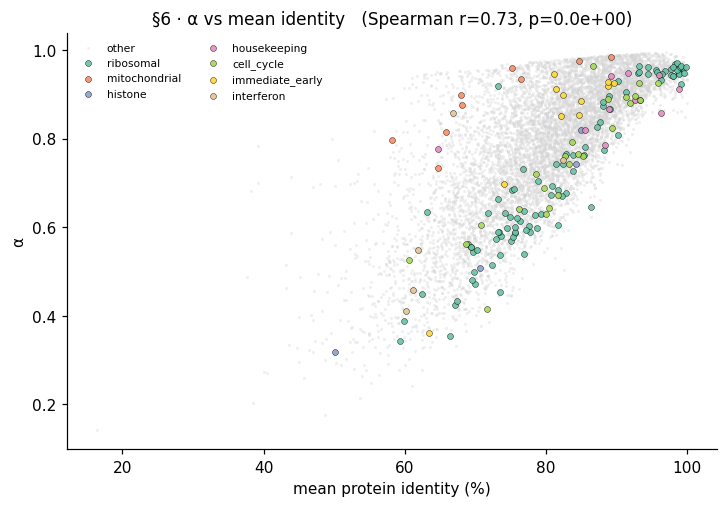

In [8]:
fig, ax = plt.subplots(figsize=(6.5, 4.5))
# plot 'other' as a faint background
other = gene_df["category"] == "other"
ax.scatter(gene_df.loc[other, "mean_identity"], gene_df.loc[other, "alpha"],
           s=4, color="lightgrey", alpha=0.35, linewidths=0, label="other")
palette = sns.color_palette("Set2", n_colors=len(pu.CATEGORY_ORDER))
for i, cat in enumerate([c for c in pu.CATEGORY_ORDER if c != "other" and c in cats_present]):
    sel = gene_df["category"] == cat
    if not sel.any():
        continue
    ax.scatter(gene_df.loc[sel, "mean_identity"], gene_df.loc[sel, "alpha"],
               s=15, color=palette[i], alpha=0.9, linewidths=0.3,
               edgecolors="black", label=cat)
ax.set_xlabel("mean protein identity (%)")
ax.set_ylabel("α")
r, p = spstats.spearmanr(gene_df["mean_identity"], gene_df["alpha"])
ax.set_title(f"§6 · α vs mean identity   (Spearman r={r:.2f}, p={p:.1e})")
ax.legend(loc="best", fontsize=7, ncol=2)
if SAVE_FIGS:
    fig.savefig(f"figs/nb13_{RUN_NAME}_alpha_vs_identity.png", bbox_inches='tight')
plt.show()


## §7 — Residual magnitude by category

The species-specific residual absorbs what the shared decoder cannot
explain. Categories with **high residual** are species-divergent — their
per-cell expression is not well-predicted by the shared decoder alone. This
should be the direct biological twin of low α.

Expect: interferon / immediate-early categories have the *highest*
residual, consistent with their low α and negative Δα.


/var/folders/y7/7c17s0l57szdjc1cdc9dmnpm0000gn/T/ipykernel_99466/2014604173.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=plot_df, x="category", y="residual_rms", ax=ax,


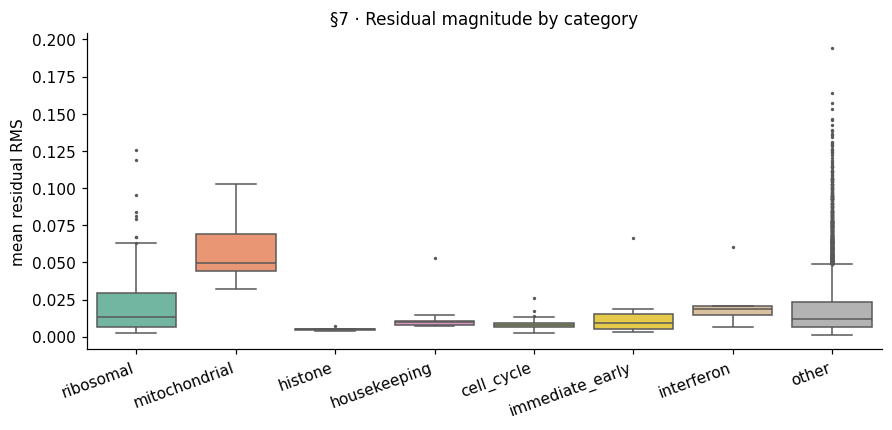

                 median    mean
category                       
mitochondrial    0.0494  0.0589
other            0.0116  0.0188
ribosomal        0.0134  0.0230
immediate_early  0.0091  0.0145
cell_cycle       0.0080  0.0088
histone          0.0048  0.0052
housekeeping     0.0098  0.0139
interferon       0.0185  0.0242


In [9]:
fig, ax = plt.subplots(figsize=(8, 3.8))
sns.boxplot(data=plot_df, x="category", y="residual_rms", ax=ax,
            order=cats_present, palette="Set2", fliersize=1.2)
ax.set_ylabel("mean residual RMS")
ax.set_xlabel("")
ax.set_title("§7 · Residual magnitude by category")
ax.set_xticklabels(ax.get_xticklabels(), rotation=20, ha="right")
if SAVE_FIGS:
    fig.savefig(f"figs/nb13_{RUN_NAME}_residual_by_cat.png", bbox_inches='tight')
plt.show()

res_tbl = plot_df.groupby("category", observed=True)["residual_rms"].agg(
    ["median", "mean"]).round(4)
print(res_tbl.to_string())


## §8 — Closing narrative

The biological predictions from Chimera's per-gene α and Δα are visible in
every panel above. A successful run should show:

- **§2** — `ribosomal`, `mitochondrial`, `histone`, `housekeeping` with
  *high* α medians (≥ 0.8 typical on close-species datasets); `interferon`,
  `immediate_early` *lower* (< 0.75).
- **§3** — positive mean Δα for the expression-conserved categories,
  negative or near-zero for the species-divergent ones.
- **§4** — `top-α` enriched for `housekeeping` / `ribosomal` with odds
  ratio > 2 and Bonferroni p < 0.05; `bot-Δα` enriched for `interferon`
  and/or `immediate_early`.
- **§5** — top-positive Δα list dominated by recognisable conserved
  genes (structural, metabolic); top-negative Δα list dominated by
  immune / stress / IEG names.
- **§7** — residual RMS *higher* for `interferon` / `immediate_early`
  than for `ribosomal` / `housekeeping`.

### What a *failing* notebook looks like (diagnostic use)

If the enrichment heatmap in §4 is uniformly grey (no significant cells),
the model has not learned category-discriminating structure — this is a
red flag that α is collapsing toward the prior or toward a constant. Cross-
check with §3 of notebook 10: if `E3.5 correction_nonzero` is failing, the
GIN is not moving α at all, and this notebook will produce noise.

### Downstream

The exported ranked tables (`tables/ranked_dalpha_{top,bot}.csv`) are
compatible with standard over-representation / GSEA tools (`gseapy`,
`enrichr`, `fgsea`). Use them for a full-scale GO-BP / MsigDB Hallmarks
analysis when a specific biological narrative is being written up.
